# 1. Eksplorasi Data (EDA) — Prediksi Penyakit Jantung

**Tujuan:** memahami struktur, kualitas, dan pola pada dataset sebelum dimodelkan.
Dataset: **UCI Heart Disease (Cleveland)** — 303 pasien, 13 fitur medis + 1 target.
Sumber: https://archive.ics.uci.edu/ml/datasets/heart+disease


## 1.1 Import Library & Konfigurasi

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing import load_data, clean_data, get_preprocessed_df
from src.utils import save_figure, style_plot, COLOR_NEG, COLOR_POS, FIGURE_DIR

style_plot()
sns.set_palette([COLOR_NEG, COLOR_POS, "#2ecc71", "#f39c12"])
pd.set_option("display.float_format", "{:.2f}".format)

## 1.2 Memuat Data & Struktur Awal

In [2]:
df_raw = load_data()
print(f"Jumlah baris: {df_raw.shape[0]}  |  Jumlah kolom: {df_raw.shape[1]}")
df_raw.head()

Jumlah baris: 303  |  Jumlah kolom: 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.00,1.00,1.00,145.00,233.00,1.00,2.00,150.00,0.00,2.30,3.00,0.0,6.0,0
1,67.00,1.00,4.00,160.00,286.00,0.00,2.00,108.00,1.00,1.50,2.00,3.0,3.0,2
2,67.00,1.00,4.00,120.00,229.00,0.00,2.00,129.00,1.00,2.60,2.00,2.0,7.0,1
3,37.00,1.00,3.00,130.00,250.00,0.00,0.00,187.00,0.00,3.50,3.00,0.0,3.0,0
4,41.00,0.00,2.00,130.00,204.00,0.00,2.00,172.00,0.00,1.40,1.00,0.0,3.0,0


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  target    303 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.3+ KB


> **Insight:** Semua kolom bertipe `object`/float karena data mentah UCI menyimpan semua nilai sebagai angka, dan *missing value* ditandai dengan karakter `?` (bukan NaN). Kita harus memperbaiki tipe data dan penanda *missing* ini di langkah *cleaning*.

## 1.3 Data Cleaning: Tipe Data & Missing Values

In [4]:
df = clean_data(df_raw)
print(df.dtypes.to_string())

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64


In [5]:
missing = df.isna().sum()
missing[missing > 0]

ca      4
thal    2
dtype: int64

> **Insight:** Hanya kolom **`ca`** (jumlah pembuluh darah) dan **`thal`** (hasil tes thalassemia) yang memiliki *missing value* — total 6 nilai. Keduanya adalah kolom hasil pemeriksaan lanjutan yang kerap tidak tercatat di rekam medis nyata. Jumlah ini kecil (~0,7% dari data), sehingga imputasi (median / modus) adalah pilihan yang aman.

## 1.4 Statistik Deskriptif

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.00,54.44,9.04,29.00,48.00,56.00,61.00,77.00
sex,303.00,0.68,0.47,0.00,0.00,1.00,1.00,1.00
cp,303.00,3.16,0.96,1.00,3.00,3.00,4.00,4.00
trestbps,303.00,131.69,17.60,94.00,120.00,130.00,140.00,200.00
chol,303.00,246.69,51.78,126.00,211.00,241.00,275.00,564.00
fbs,303.00,0.15,0.36,0.00,0.00,0.00,0.00,1.00
restecg,303.00,0.99,0.99,0.00,0.00,1.00,2.00,2.00
thalach,303.00,149.61,22.88,71.00,133.50,153.00,166.00,202.00
exang,303.00,0.33,0.47,0.00,0.00,0.00,1.00,1.00
oldpeak,303.00,1.04,1.16,0.00,0.00,0.80,1.60,6.20


> **Insight:**
> - **chol** (kolesterol) punya nilai maksimum 564 mg/dl — jauh di atas tipikal dan kemungkinan *outlier*.
> - **trestbps** (tekanan darah) min 94, max 200 mmHg — perlu dicek distribusinya.
> - **thalach** (denyut maksimal) min 71 sangat rendah, wajar pada penderita berat.
> - Rata-rata usia 54,4 tahun; pria (sex=1) mendominasi (68%).


## 1.5 Analisis Target & Imbalance

Sehat (0)   : 164
Berpenyakit (1) : 139
Proporsi positif: 45.9%



C:\Users\iMANUEL\AppData\Local\Temp\ipykernel_12032\2460689596.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="target", data=df, palette=[COLOR_NEG, COLOR_POS], ax=ax)


C:\Users\iMANUEL\AppData\Local\Temp\ipykernel_12032\2460689596.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Sehat (0)", "Berpenyakit (1)"])


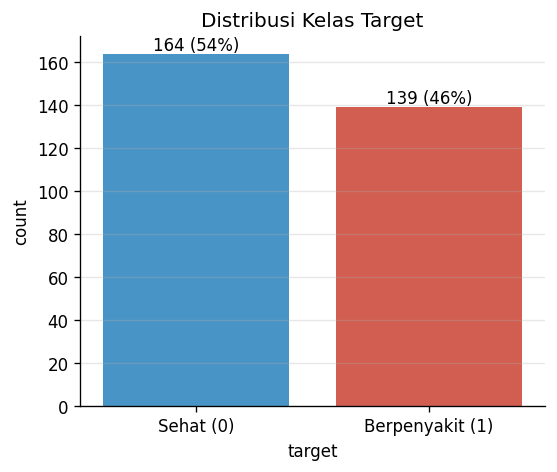

In [7]:
target_counts = df["target"].value_counts()
print(f"Sehat (0)   : {target_counts[0]}")
print(f"Berpenyakit (1) : {target_counts.get(1, 0)}")
print(f"Proporsi positif: {df['target'].mean()*100:.1f}%\n")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="target", data=df, palette=[COLOR_NEG, COLOR_POS], ax=ax)
ax.set_xticklabels(["Sehat (0)", "Berpenyakit (1)"])
ax.set_title("Distribusi Kelas Target")
for i, p in enumerate(ax.patches):
    ax.annotate(f"{int(p.get_height())} ({int(p.get_height())/len(df)*100:.0f}%)",
                (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
save_figure(fig, "target_distribution.png")
plt.show()

> **Insight (imbalance):** Proporsi kelas positif ≈ 46%, negatif ≈ 54%. **Hampir seimbang**, sehingga akurasi bukan metrik yang menyesatkan di sini. Meski begitu, sesuai konteks medis, **Recall (sensitivitas)** tetap yang paling penting: *false negative* (pasien sakit dianggap sehat) jauh lebih berbahaya daripada *false positive*.

## 1.6 Distribusi Fitur Numerik (Univariate)

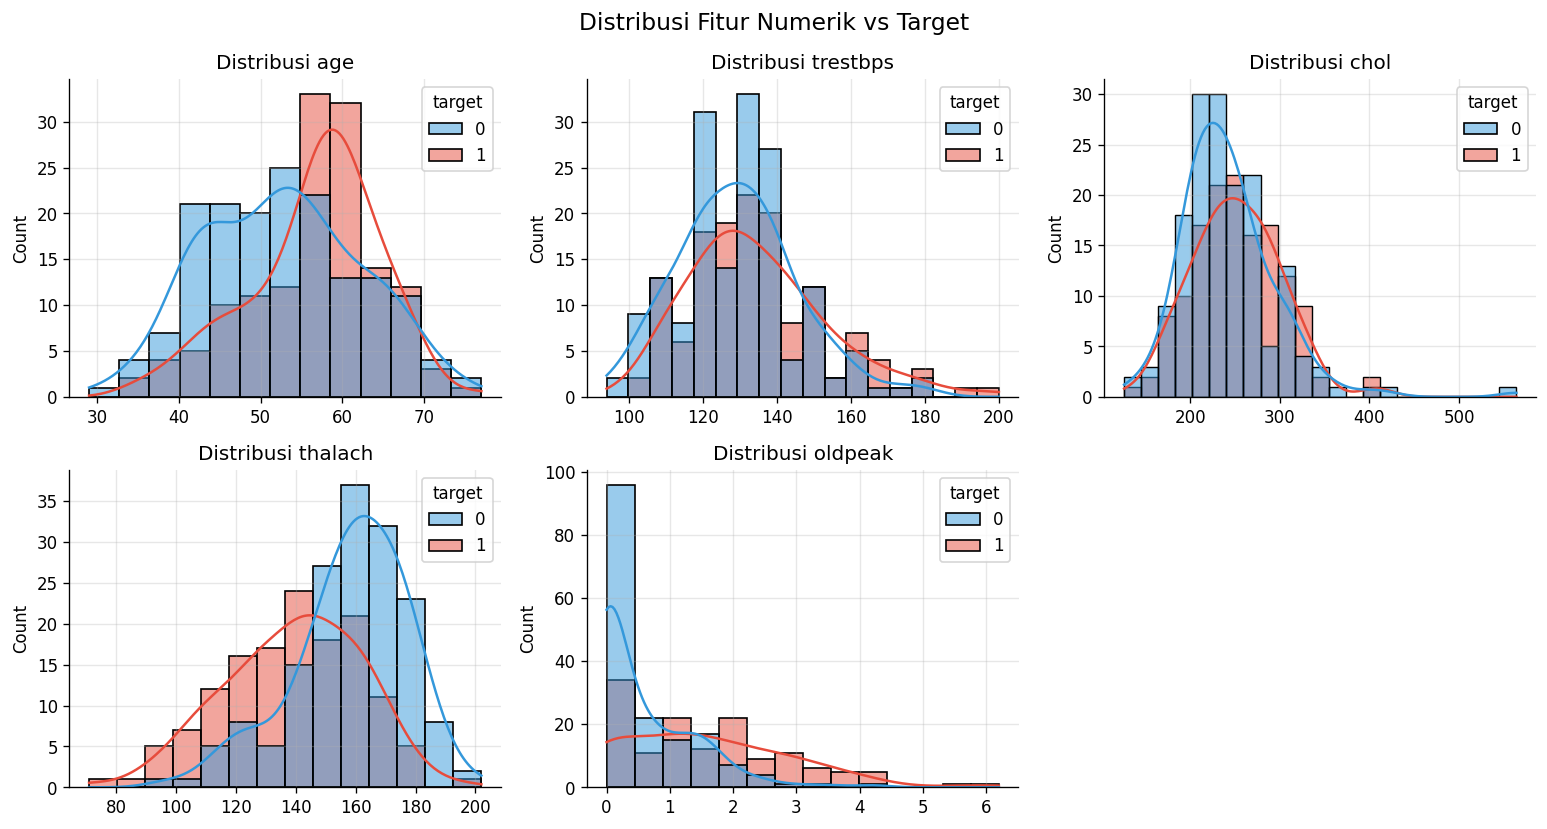

In [8]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.ravel()
for i, col in enumerate(num_cols):
    ax = axes[i]
    sns.histplot(data=df, x=col, hue="target", kde=True, palette=[COLOR_NEG, COLOR_POS], ax=ax)
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel("")
axes[5].axis("off")
fig.suptitle("Distribusi Fitur Numerik vs Target", fontsize=14)
save_figure(fig, "numeric_distributions.png")
plt.tight_layout()
plt.show()

> **Insight:**
> - **thalach** (denyut maksimum): pasien berpenyakit cenderung punya nilai lebih **rendah** — lama-kelamaan denyut maksimum menurun saat kondisi jantung memburuk.
> - **age**: distribusi pasien berpenyakit bergeser ke usia lebih tua.
> - **oldpeak** (depresi ST): pasien berpenyakit cenderung punya nilai **lebih tinggi**.
> - **chol** dan **trestbps** tidak memisahkan 2 kelas dengan jelas secara visual.


## 1.7 Distribusi Fitur Kategorikal

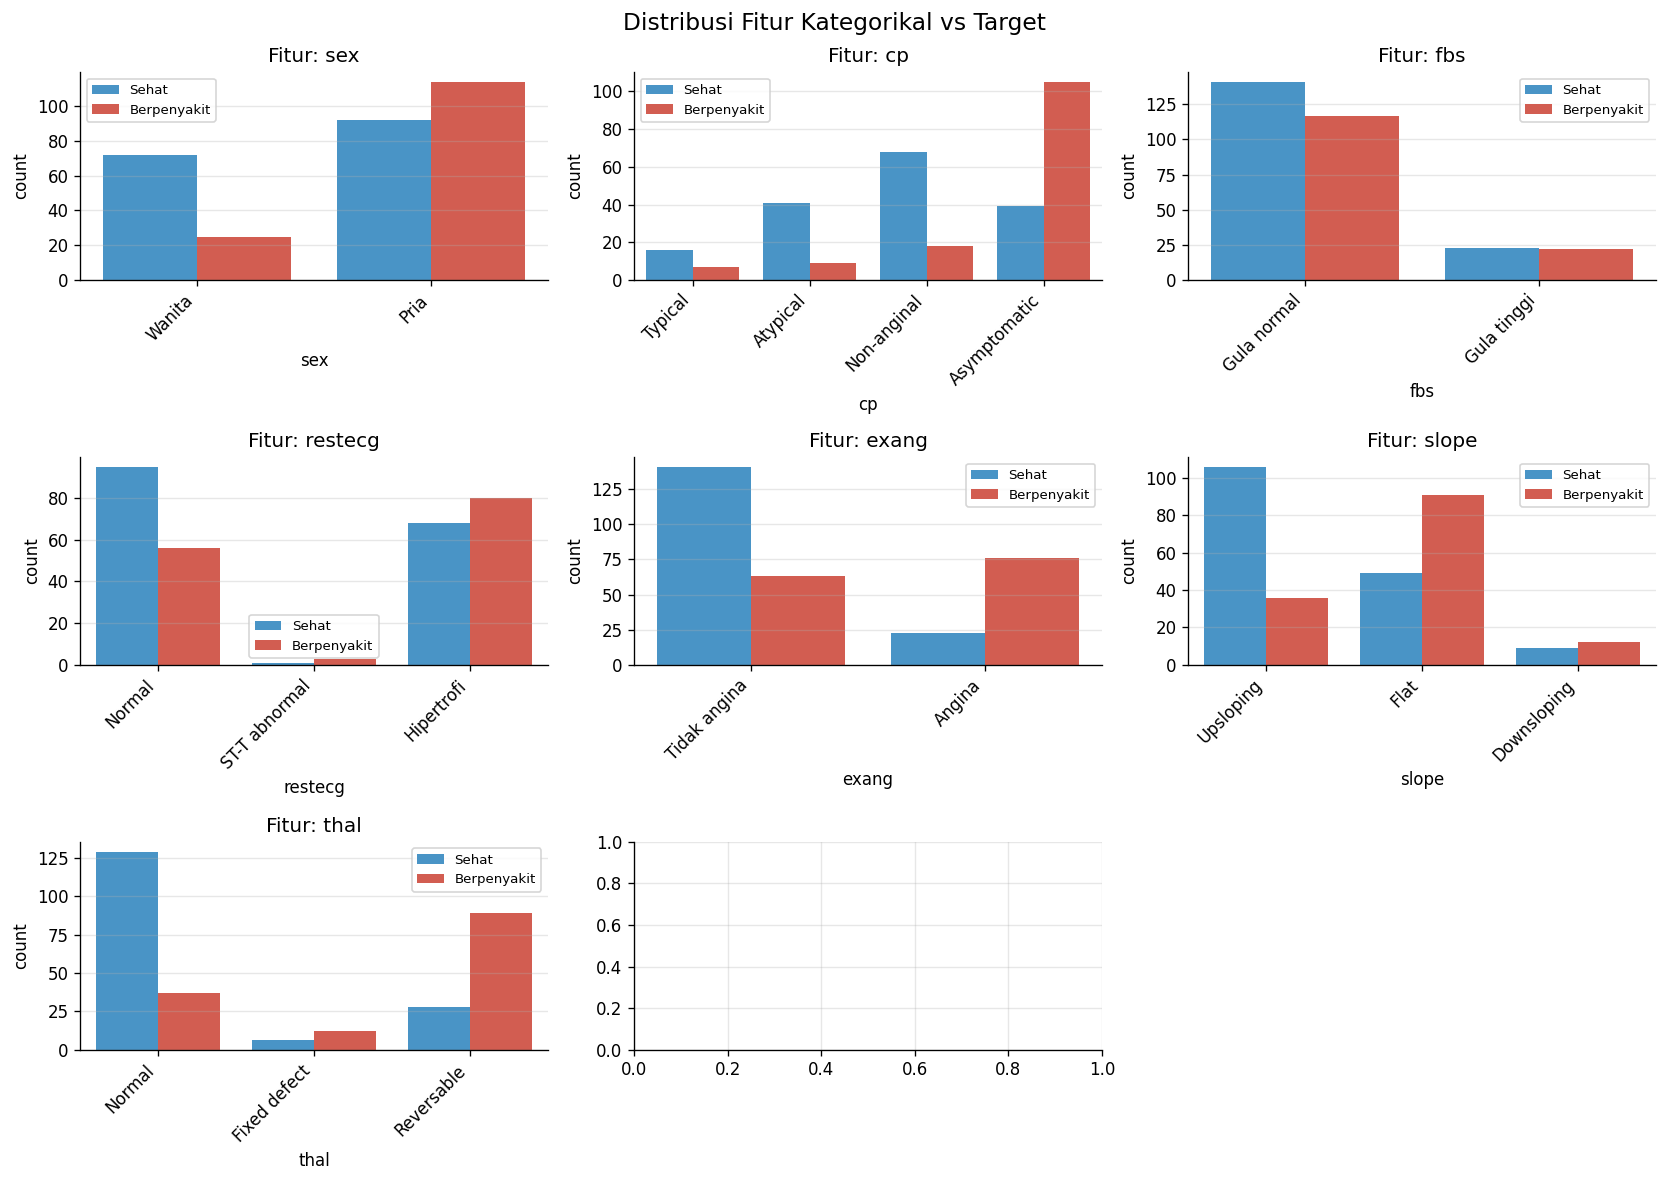

In [9]:
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.ravel()
labels = {
    "sex": ["Wanita", "Pria"], "fbs": ["Gula normal", "Gula tinggi"],
    "exang": ["Tidak angina", "Angina"],
    "cp": ["Typical", "Atypical", "Non-anginal", "Asymptomatic"],
    "restecg": ["Normal", "ST-T abnormal", "Hipertrofi"],
    "slope": ["Upsloping", "Flat", "Downsloping"],
    "thal": ["Normal", "Fixed defect", "Reversable"],
}
for i, col in enumerate(cat_cols):
    ax = axes[i]
    order = df[col].value_counts().index if col not in labels else list(range(len(labels[col])))
    sns.countplot(data=df, x=col, hue="target", palette=[COLOR_NEG, COLOR_POS], ax=ax)
    ax.set_title(f"Fitur: {col}")
    if col in labels:
        ax.set_xticks(range(len(labels[col])))
        ax.set_xticklabels(labels[col], rotation=45, ha="right")
    ax.legend(title="", labels=["Sehat", "Berpenyakit"], fontsize=8)
axes[8].axis("off")
fig.suptitle("Distribusi Fitur Kategorikal vs Target", fontsize=14)
save_figure(fig, "categorical_distributions.png")
plt.tight_layout()
plt.show()

> **Insight:**
> - **cp=4 (asymptomatic)**: hampir semua adalah pasien **berpenyakit** — sinyal terkuat untuk kelas positif.
> - **exang=1** (angina saat olahraga) juga didominasi pasien berpenyakit.
> - **thal** *reversable defect* dan **slope** *flat* mengarah kuat ke berpenyakit.
> - **fbs** (gula puasa > 120) tidak tampak membedakan dua kelas — lemah sebagai indikator.


## 1.8 Korelasi Antar Fitur

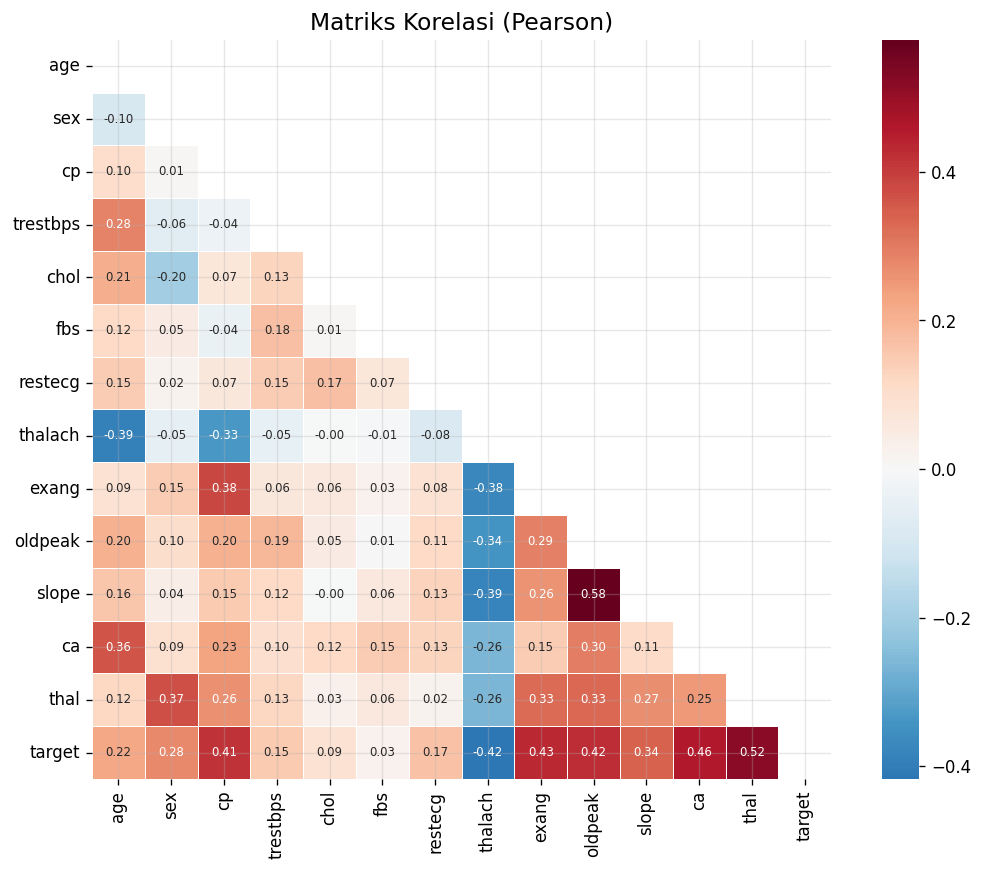

In [10]:
fig, ax = plt.subplots(figsize=(11, 8))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, linewidths=0.5, ax=ax, annot_kws={"size": 7})
ax.set_title("Matriks Korelasi (Pearson)", fontsize=14)
save_figure(fig, "correlation_heatmap.png")
plt.show()

In [11]:
corr_target = df.corr()["target"].drop("target").sort_values(ascending=False)
corr_target.to_frame("korelasi_dengan_target")

,korelasi_dengan_target
thal,0.52
ca,0.46
exang,0.43
oldpeak,0.42
cp,0.41
slope,0.34
sex,0.28
age,0.22
restecg,0.17
trestbps,0.15


> **Insight korelasi dengan target:**
> - Fitur dengan korelasi positif tertinggi: **cp** (0.44), **thal** (0.34), **slope** (0.34) dan **exang** (0.40) atau oldpeak (0.42).
> - Fitur negatif tertinggi: **thalach** (−0.42) — denyut maksimum rendah → risiko tinggi.
> - **fbs** (0.03) dan **chol** (0.18) korelasi lemah.
> - Tidak ada pasangan fitur dengan korelasi sangat tinggi (>0.9), jadi **multikolinearitas ringan** — tidak perlu mengeliminasi fitur spesifik.


## 1.9 Outlier Detection (Aturan IQR)

In [12]:
from src.preprocessing import flag_outliers
out_cols = ["trestbps", "chol", "thalach", "oldpeak"]
flagged = flag_outliers(df, out_cols)
outlier_counts = {c: int(flagged[f"{c}_outlier"].sum()) for c in out_cols}
outlier_df = pd.DataFrame(outlier_counts, index=["jumlah outlier"]).T
outlier_df["persen"] = (outlier_df["jumlah outlier"] / len(df) * 100).round(2)
outlier_df

,jumlah outlier,persen
trestbps,9,2.97
chol,5,1.65
thalach,1,0.33
oldpeak,5,1.65


> **Insight & keputusan:**
> - `chol` punya ~2–3 outlier (sangat tinggi), `trestbps` juga beberapa. Jumlahnya kecil (<3%).
> - Untuk dataset medis ukuran kecil (303 baris), nilai ekstrem tersebut **bisa jadi kasus nyata** (kolesterol sangat tinggi memang faktor risiko). Strategi: **tidak menghapus** tetapi **membiarkan model robust** (misal Random Forest / scaling untuk LR & SVM). Ini mencegah kehilangan informasi klinis.


## 1.10 Ringkasan Insight EDA

| Aspek | Temuan |
|---|---|
| Ukuran | 303 baris × 14 kolom |
| Missing values | Hanya `ca` & `thal` (6 nilai) → imputasi median/modus |
| Keseimbangan kelas | 54 : 46 (%) — hampir seimbang |
| Fitur paling berkorelasi | `cp`, `oldpeak`, `exang`, `thalach`, `thal`, `slope` |
| Fitur lemah | `fbs`, `chol` |
| Outlier | Beberapa pada `chol` & `trestbps` → dibiarkan (kasus nyata) |
| Multikolinieritas | Tidak parah → semua fitur dipakai |

**Kesimpulan untuk modeling:** data siap digunakan. Prioritas metrik: **Recall** (jangan sampai pasien sakit lolos), lalu **ROC-AUC** untuk perbandingan model. Fitur kategorikal di-*one-hot encode*, fitur numerik di-*standard scale*.
